## Análise de desempenho operacional e cancelamentos em solicitações de corridas por carro de aplicativo

Importando as bibliotecas

In [16]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [17]:
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt

Lendo o dataset

In [18]:
df = pd.read_csv("../dados/dados_brutos/uber_ride_bookings.csv")

A inspeção inicial busca compreender a estrutura do conjunto de dados, identificar as variáveis disponíveis e verificar seus tipos e preenchimento. Para isso, são examinados os primeiros registros, as dimensões da base e um resumo das informações de cada coluna.

In [19]:
df.head()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


In [20]:
df.shape

(150000, 21)

O conjunto de dados contém 150.000 registros e 21 colunas. As variáveis incluem informações sobre as solicitações, os clientes, as categorias de veículos, os locais de embarque e destino, os tempos operacionais, os valores e as avaliações. As colunas de data e horário foram importadas como texto e precisarão ser convertidas para permitir análises temporais. Também foram identificados valores ausentes, cuja interpretação depende da situação de cada solicitação.


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  str    
 1   Time                               150000 non-null  str    
 2   Booking ID                         150000 non-null  str    
 3   Booking Status                     150000 non-null  str    
 4   Customer ID                        150000 non-null  str    
 5   Vehicle Type                       150000 non-null  str    
 6   Pickup Location                    150000 non-null  str    
 7   Drop Location                      150000 non-null  str    
 8   Avg VTAT                           139500 non-null  float64
 9   Avg CTAT                           102000 non-null  float64
 10  Cancelled Rides by Customer        10500 non-null   float64
 11  Reason for cancelling by Customer  10500 non-null 

As estatísticas descritivas permitem examinar a tendência central, a dispersão e os limites dos valores numéricos. Foram observadas a média, a mediana, o desvio-padrão, os quartis e os valores mínimos e máximos, considerando os registros preenchidos em cada variável.

In [22]:
df.describe()

,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Cancelled Rides by Driver,Incomplete Rides,Booking Value,Ride Distance,Driver Ratings,Customer Rating
count,139500.000000,102000.000000,10500.0,27000.0,9000.0,102000.000000,102000.000000,93000.000000,93000.000000
mean,8.456352,29.149636,1.0,1.0,1.0,508.295912,24.637012,4.230992,4.404584
std,3.773564,8.902577,0.0,0.0,0.0,395.805774,14.002138,0.436871,0.437819
min,2.000000,10.000000,1.0,1.0,1.0,50.000000,1.000000,3.000000,3.000000
25%,5.300000,21.600000,1.0,1.0,1.0,234.000000,12.460000,4.100000,4.200000
50%,8.300000,28.800000,1.0,1.0,1.0,414.000000,23.720000,4.300000,4.500000
75%,11.300000,36.800000,1.0,1.0,1.0,689.000000,36.820000,4.600000,4.800000
max,20.000000,45.000000,1.0,1.0,1.0,4277.000000,50.000000,5.000000,5.000000


Entre os registros disponíveis, o tempo médio de chegada do motorista é de aproximadamente 8,46 minutos, enquanto o tempo médio de viagem é de 29,15 minutos. O valor das solicitações apresenta média de 508,30 e mediana de 414,00, o que sugere assimetria à direita, a ser investigada graficamente. Essas medidas utilizam quantidades diferentes de observações devido aos valores ausentes.

In [23]:
df.isnull().sum()

Date                                      0
Time                                      0
Booking ID                                0
Booking Status                            0
Customer ID                               0
Vehicle Type                              0
Pickup Location                           0
Drop Location                             0
Avg VTAT                              10500
Avg CTAT                              48000
Cancelled Rides by Customer          139500
Reason for cancelling by Customer    139500
Cancelled Rides by Driver            123000
Driver Cancellation Reason           123000
Incomplete Rides                     141000
Incomplete Rides Reason              141000
Booking Value                         48000
Ride Distance                         48000
Driver Ratings                        57000
Customer Rating                       57000
Payment Method                        48000
dtype: int64

Nas variáveis examinadas, os valores ausentes apresentam um padrão associado ao status da solicitação. As avaliações estão disponíveis apenas para corridas concluídas, enquanto os motivos de cancelamento e de interrupção aparecem exclusivamente nas situações correspondentes. Por esse motivo, os valores ausentes serão preservados, sem preenchimento geral com zero ou exclusão de linhas. Cada análise utilizará o recorte de registros adequado à pergunta investigada.

In [24]:
resumo_ausentes = pd.DataFrame({
    "quantidade_ausente": df.isna().sum(),
    "percentual_ausente": df.isna().mean().mul(100)
})

resumo_ausentes.sort_values(
    "percentual_ausente",
    ascending=False
).round(2)

,quantidade_ausente,percentual_ausente
Incomplete Rides Reason,141000,94.0
Incomplete Rides,141000,94.0
Reason for cancelling by Customer,139500,93.0
Cancelled Rides by Customer,139500,93.0
Cancelled Rides by Driver,123000,82.0
Driver Cancellation Reason,123000,82.0
Driver Ratings,57000,38.0
Customer Rating,57000,38.0
Avg CTAT,48000,32.0
Ride Distance,48000,32.0


O preenchimento das variáveis será examinado por status da solicitação. Essa comparação permite verificar se as ausências estão relacionadas ao andamento da corrida, como a inexistência de avaliações em solicitações não concluídas ou de motivos de cancelamento em corridas concluídas.

In [25]:
colunas_investigadas = [
    "Avg VTAT",
    "Avg CTAT",
    "Booking Value",
    "Ride Distance",
    "Driver Ratings",
    "Customer Rating",
    "Payment Method",
    "Reason for cancelling by Customer",
    "Driver Cancellation Reason",
    "Incomplete Rides Reason"
]

ausentes_por_status = (
    df.groupby("Booking Status")[colunas_investigadas]
      .agg(lambda coluna: coluna.isna().mean() * 100)
      .round(2)
)

ausentes_por_status.T

Booking Status,Cancelled by Customer,Cancelled by Driver,Completed,Incomplete,No Driver Found
Avg VTAT,0.0,0.0,0.0,0.0,100.0
Avg CTAT,100.0,100.0,0.0,0.0,100.0
Booking Value,100.0,100.0,0.0,0.0,100.0
Ride Distance,100.0,100.0,0.0,0.0,100.0
Driver Ratings,100.0,100.0,0.0,100.0,100.0
Customer Rating,100.0,100.0,0.0,100.0,100.0
Payment Method,100.0,100.0,0.0,0.0,100.0
Reason for cancelling by Customer,0.0,100.0,100.0,100.0,100.0
Driver Cancellation Reason,100.0,0.0,100.0,100.0,100.0
Incomplete Rides Reason,100.0,100.0,100.0,0.0,100.0


### Verifica valores repetidos e duplicados 

A verificação de duplicidades considera tanto linhas completamente iguais quanto repetições do identificador da solicitação. Essas situações serão avaliadas separadamente, pois um identificador repetido pode estar associado a registros com informações diferentes e não justifica, por si só, a exclusão de uma linha.

In [26]:
print("Linhas totalmente duplicadas:", df.duplicated().sum())

print(
    "Ocorrências adicionais de IDs de solicitação:",
    df["Booking ID"].duplicated().sum()
)

Linhas totalmente duplicadas: 0
Ocorrências adicionais de IDs de solicitação: 1233


In [27]:
ids_repetidos = df[
    df["Booking ID"].duplicated(keep=False)
].sort_values("Booking ID")

ids_repetidos.head(10)

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
9192,2024-07-21,17:59:41,"""CNR1026036""",No Driver Found,"""CID6974869""",Go Mini,Seelampur,Nehru Place,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
81334,2024-10-15,18:17:23,"""CNR1026036""",Completed,"""CID6480133""",Go Mini,Khandsa,Ashok Vihar,3.8,43.3,...,NaN,NaN,NaN,NaN,NaN,102.0,36.51,4.9,4.2,UPI
1353,2024-01-19,17:00:57,"""CNR1029172""",Incomplete,"""CID2615731""",Bike,Jhilmil,Narsinghpur,4.7,26.7,...,NaN,NaN,NaN,1.0,Customer Demand,429.0,16.16,NaN,NaN,UPI
9587,2024-12-17,19:19:02,"""CNR1029172""",Completed,"""CID6382731""",Auto,Inderlok,Laxmi Nagar,6.9,34.4,...,NaN,NaN,NaN,NaN,NaN,332.0,36.38,4.3,4.3,UPI
82029,2024-11-05,16:50:20,"""CNR1051228""",Completed,"""CID3177617""",Auto,Dwarka Sector 21,Nehru Place,8.5,24.8,...,NaN,NaN,NaN,NaN,NaN,246.0,4.80,4.6,4.5,UPI
110412,2024-01-31,08:42:04,"""CNR1051228""",Completed,"""CID5242056""",Premier Sedan,Arjangarh,Yamuna Bank,14.2,25.4,...,NaN,NaN,NaN,NaN,NaN,930.0,13.06,3.4,4.2,Cash
87333,2024-04-20,23:16:21,"""CNR1056023""",Completed,"""CID9367665""",Premier Sedan,Badshahpur,Sultanpur,7.1,25.7,...,NaN,NaN,NaN,NaN,NaN,116.0,46.54,3.8,5.0,Credit Card
120008,2024-07-07,17:18:49,"""CNR1056023""",Incomplete,"""CID4890470""",Go Sedan,Meerut,Tilak Nagar,6.6,24.2,...,NaN,NaN,NaN,1.0,Customer Demand,420.0,5.13,NaN,NaN,Uber Wallet
38548,2024-10-15,13:33:55,"""CNR1058956""",Completed,"""CID1882606""",Go Mini,Badshahpur,MG Road,3.7,20.2,...,NaN,NaN,NaN,NaN,NaN,194.0,24.65,4.3,4.3,Cash
71570,2024-02-12,19:02:47,"""CNR1058956""",Cancelled by Customer,"""CID2451799""",Premier Sedan,Patel Chowk,Kaushambi,19.9,NaN,...,Wrong Address,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Não foram encontradas linhas completamente duplicadas. Entretanto, foram identificadas 1.233 ocorrências adicionais de identificadores de solicitação. Na amostra examinada, esses identificadores estão associados a registros com datas, clientes e outras características diferentes. Optou-se por preservar os registros e documentar a ausência de unicidade dessa coluna. Nas análises descritivas, a unidade de contagem será cada linha da base, sem pressupor que o identificador represente uma solicitação única.

In [28]:
df["data_hora_solicitacao"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

print(
    "Registros com data ou horário inválido:",
    df["data_hora_solicitacao"].isna().sum()
)

df["hora"] = df["data_hora_solicitacao"].dt.hour
df["dia_semana"] = df["data_hora_solicitacao"].dt.dayofweek
df["mes"] = df["data_hora_solicitacao"].dt.month

Registros com data ou horário inválido: 0


A conversão das datas e dos horários foi concluída sem gerar valores temporais ausentes. Foram criadas as variáveis de hora, dia da semana e mês, que serão utilizadas para investigar a distribuição temporal das solicitações.

## Distribuição dos status das corridas

A distribuição dos status permite identificar a proporção de solicitações que resultam em corridas concluídas e a participação dos diferentes desfechos. Cancelamentos pelo cliente, cancelamentos pelo motorista, ausência de motorista e corridas incompletas serão apresentados separadamente, pois representam situações operacionais distintas.

In [29]:
resumo_status = (
    df["Booking Status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .to_frame("quantidade")
)

resumo_status["percentual"] = (
    resumo_status["quantidade"] / len(df) * 100
).round(2)

resumo_status

,quantidade,percentual
status,,
Completed,93000,62.0
Cancelled by Driver,27000,18.0
No Driver Found,10500,7.0
Cancelled by Customer,10500,7.0
Incomplete,9000,6.0


In [31]:
contagem_veiculos = pd.crosstab(
    df["Vehicle Type"],
    df["Booking Status"]
)

resumo_veiculos = pd.DataFrame(index=contagem_veiculos.index)

resumo_veiculos["total_solicitacoes"] = contagem_veiculos.sum(axis=1)

resumo_veiculos["canceladas_cliente"] = contagem_veiculos[
    "Cancelled by Customer"
]

resumo_veiculos["canceladas_motorista"] = contagem_veiculos[
    "Cancelled by Driver"
]

resumo_veiculos["taxa_cancelamento_cliente"] = (
    resumo_veiculos["canceladas_cliente"]
    / resumo_veiculos["total_solicitacoes"] * 100
)

resumo_veiculos["taxa_cancelamento_motorista"] = (
    resumo_veiculos["canceladas_motorista"]
    / resumo_veiculos["total_solicitacoes"] * 100
)

resumo_veiculos["taxa_cancelamento_total"] = (
    resumo_veiculos["taxa_cancelamento_cliente"]
    + resumo_veiculos["taxa_cancelamento_motorista"]
)

resumo_veiculos = resumo_veiculos.sort_values(
    "taxa_cancelamento_total",
    ascending=False
)

resumo_veiculos.round(2)

,total_solicitacoes,canceladas_cliente,canceladas_motorista,taxa_cancelamento_cliente,taxa_cancelamento_motorista,taxa_cancelamento_total
Vehicle Type,,,,,,
Go Sedan,27141,1832,5031,6.75,18.54,25.29
Bike,22517,1575,4077,6.99,18.11,25.10
Premier Sedan,18111,1266,3250,6.99,17.94,24.94
Go Mini,29806,2097,5330,7.04,17.88,24.92
Auto,37419,2680,6643,7.16,17.75,24.92
eBike,10557,723,1907,6.85,18.06,24.91
Uber XL,4449,327,762,7.35,17.13,24.48


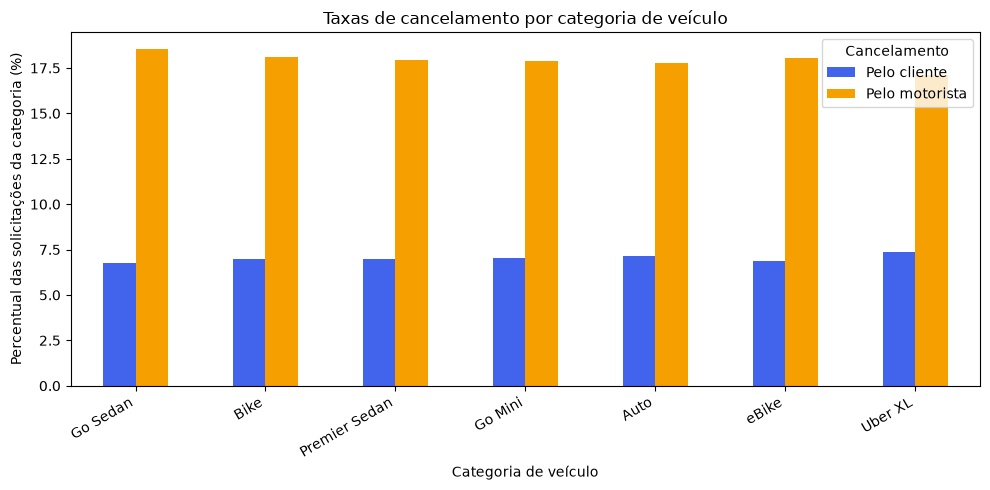

In [32]:
taxas = resumo_veiculos[
    ["taxa_cancelamento_cliente", "taxa_cancelamento_motorista"]
].rename(columns={
    "taxa_cancelamento_cliente": "Pelo cliente",
    "taxa_cancelamento_motorista": "Pelo motorista"
})

ax = taxas.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#4263EB", "#F59F00"]
)

ax.set_title("Taxas de cancelamento por categoria de veículo")
ax.set_xlabel("Categoria de veículo")
ax.set_ylabel("Percentual das solicitações da categoria (%)")
ax.legend(title="Cancelamento")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()